In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

In [2]:
plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": False,
    "ytick.right": False,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    "xtick.major.size": 6,
    "ytick.major.size": 6,
    "xtick.minor.size": 3,
    "ytick.minor.size": 3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
    "xtick.minor.width": 0.8,
    "ytick.minor.width": 0.8,
    "figure.dpi": 150,
    "savefig.dpi": 300,
})


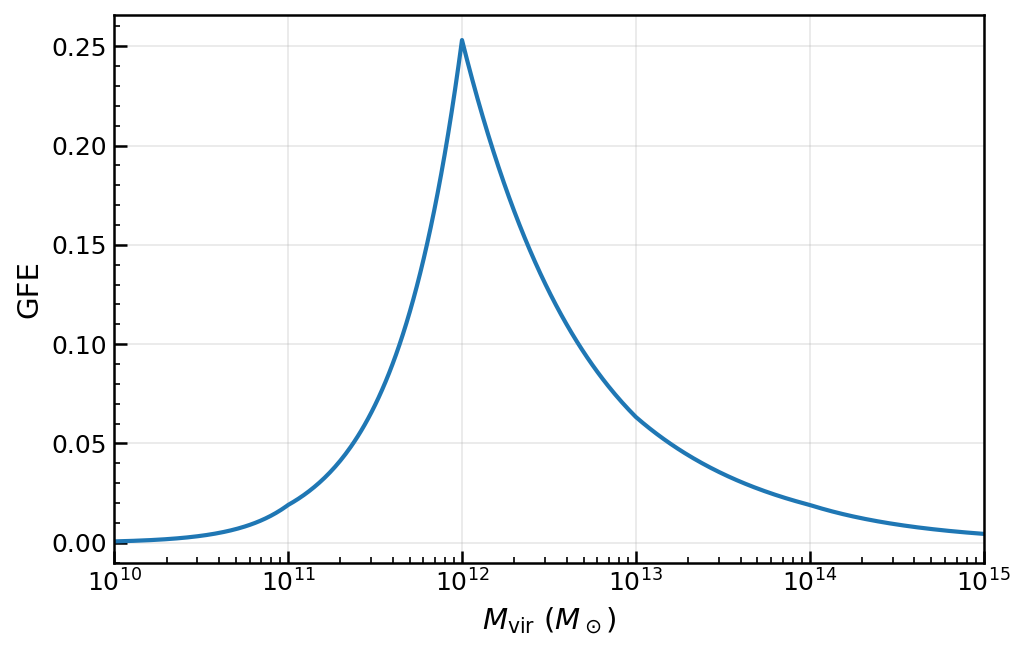

In [3]:
# Values from the SMHM plot (approximated  by eye)
Mvir = np.array([1e10, 1e11, 1e12, 1e13, 1e14, 1e15])
Mstar = np.array([1e6, 3e8, 4e10, 1e11, 3e11, 7e11])

# Universal baryon fraction
fb = 0.158

# Smooth interpolation in log-space
log_Mvir = np.log10(Mvir)
log_Mstar = np.log10(Mstar)

log_Mvir_smooth = np.arange(10, 15.001, 0.01)
log_Mstar_smooth = np.interp(log_Mvir_smooth, log_Mvir, log_Mstar)

Mvir_smooth = 10**log_Mvir_smooth
Mstar_smooth = 10**log_Mstar_smooth

GFE = Mstar_smooth / (fb * Mvir_smooth)

# Plot
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(Mvir_smooth, GFE, linewidth = 2)

ax.set_xscale("log")
ax.set_xlabel(r"$M_{\rm vir}\ (M_\odot)$")
ax.set_ylabel("GFE")

ax.set_xlim(1e10, 1e15)
ax.set_ylim(bottom = -0.01)

ax.set_xticks(10.0**np.arange(10, 16))
ax.grid(alpha = 0.3)

plt.tight_layout()
plt.show()


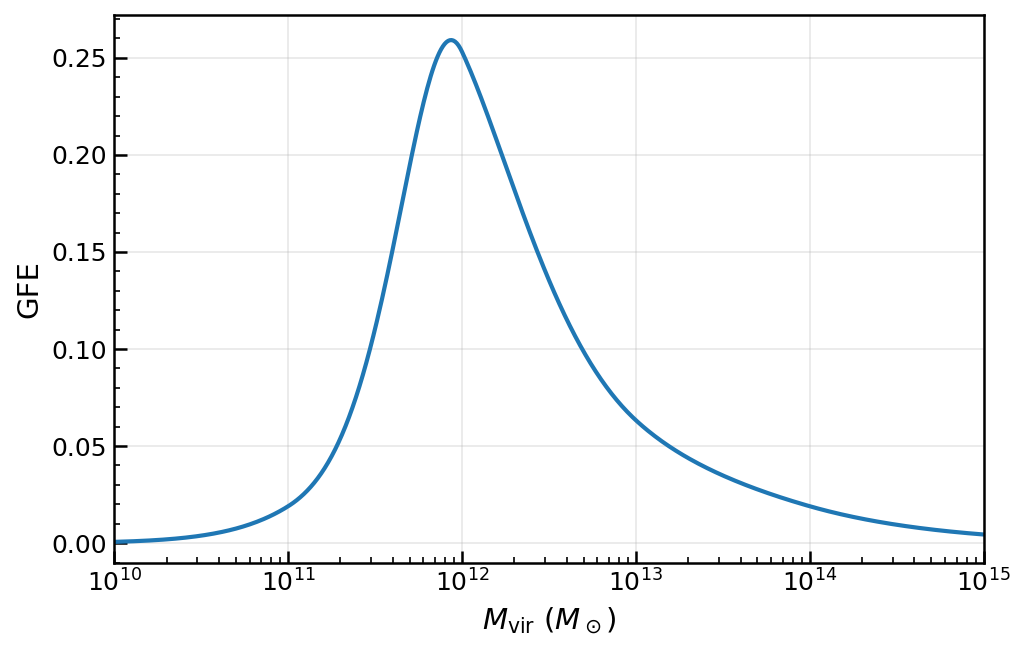

In [4]:
# Interpolation via PchipInterpolator
interp = PchipInterpolator(log_Mvir, log_Mstar)
log_Mstar_smoother = interp(log_Mvir_smooth)

Mvir_smooth = 10**log_Mvir_smooth
Mstar_smoother = 10**log_Mstar_smoother

GFE_smoother = Mstar_smoother / (fb * Mvir_smooth)

# Plot
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(Mvir_smooth, GFE_smoother, linewidth = 2)

ax.set_xscale("log")
ax.set_xlabel(r"$M_{\rm vir}\ (M_\odot)$")
ax.set_ylabel("GFE")

ax.set_xlim(1e10, 1e15)
ax.set_ylim(bottom = -0.01)

ax.set_xticks(10.0**np.arange(10, 16))
ax.grid(alpha = 0.3)

plt.tight_layout()
plt.show()
